## 02 - Audio Representations: Handcrafted Features and CLAP/MERT/MuQ embeddings
**Research question:** Which acoustic representations help distinguish the five music generators, and do the generators show visible structure in high-dimensional embedding spaces?

We analyze 36 handcrafted acoustic features and three frozen pretrained audio encoders: CLAP, MERT-v1-95M and MuQ-large. This notebook covers feature extraction/reuse, handcrafted ablation and exploratory PCA/UMAP plots. Classification benchmarks and test-set error analysis belong to notebooks 03 and 04.

Reproducibility: Set `DATASET_MODE` to `pilot` (3,000 clips) or `full` (27,605 clips). Existing CSV/NPZ files are reused. PCA/UMAP are for visualization only, not model training.

## Setup and dataset
To visualize already-computed representations you do not need to run WAV preprocessing, CLAP/MERT/MuQ extraction, or install muq just to visualize existing .npz files. Make sure the files `split_metadata.csv`, `clap_embeddings_full.npz`, `mert_embeddings_full.npz`, and `muq_embeddings_full.npz` are in `data/interim/`. Extraction blocks remain available for future runs but are disabled by default.

In [4]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ai_music_origin.data import load_audio, preprocess_audio
from ai_music_origin.features import extract_handcrafted_features

In [6]:
DATASET_MODE = "full"  # "pilot" or "full"
# Reuse already-computed complete outputs unless you intentionally need to regenerate them.
RECOMPUTE_HANDCRAFTED = False
RECOMPUTE_CLAP = False

# New MERT experiments; enable the smoke test first, then the full extraction.
RUN_MERT_SMOKE_TEST = False
RUN_MERT_EXTRACTION = False
RECOMPUTE_MERT = False
MERT_CHECKPOINT_EVERY = 100

# MuQ: first run a one-clip smoke test, then enable extraction.
RUN_MUQ_SMOKE_TEST = False
RUN_MUQ_EXTRACTION = False
RECOMPUTE_MUQ = False
MUQ_CHECKPOINT_EVERY = 100

In [7]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.environ['HF_HOME'] = str(PROJECT_ROOT / '.cache' / 'huggingface')

metadata_filename = ("split_metadata.csv" if DATASET_MODE == "full" else "pilot_metadata.csv")
suffix = "_full" if DATASET_MODE == "full" else ""
METADATA_PATH = PROJECT_ROOT / "data/interim" / metadata_filename
HANDCRAFTED_PATH = (PROJECT_ROOT / "data/interim" / f"handcrafted_features{suffix}.csv")
CLAP_PATH = (PROJECT_ROOT / "data/interim" / f"clap_embeddings{suffix}.npz")
dataset_df = pd.read_csv(METADATA_PATH, dtype={"track_id": str})
print('Pilot:', len(dataset_df), 'clips; predefined splits:', dataset_df['split'].value_counts().to_dict())


Pilot: 27605 clips; predefined splits: {'train': 19320, 'test': 4145, 'validation': 4140}


## Handcrafted feature extraction

We extract acoustic features that describe different properties of the audio signal.

The feature groups include:
- energy-related features
- temporal features
- spectral features
- MFCCs

Most features are calculated over short frames of the audio signal. We use their mean and standard deviation to create one fixed-size feature vector for each audio clip.

Before feature extraction, every audio clip is trimmed or padded to 10 seconds. Amplitude normalization is not applied because amplitude differences can contain useful information about the generators.

In [7]:
if RECOMPUTE_HANDCRAFTED or not HANDCRAFTED_PATH.exists():
    all_features = []
    for _, row in dataset_df.iterrows():
        audio, sr = load_audio(row["path"])
        audio_processed = preprocess_audio(audio, sr, target_duration=10.0, normalize=False)
        features = extract_handcrafted_features(audio_processed, sr)
        features["track_id"] = row["track_id"]
        features["generator"] = row["generator"]
        features["split"] = row["split"]
        all_features.append(features)
    handcrafted_df = pd.DataFrame(all_features)
    HANDCRAFTED_PATH.parent.mkdir(parents=True, exist_ok=True)
    handcrafted_df.to_csv(HANDCRAFTED_PATH, index=False)
else:
    handcrafted_df = pd.read_csv(HANDCRAFTED_PATH)
eda_df = handcrafted_df.loc[handcrafted_df['split'] == 'train'].copy()
print('Handcrafted feature columns:', handcrafted_df.shape[1] - 3)
    

Handcrafted feature columns: 36


Handcrafted feature extraction is complete for the selected dataset. Each sample contains 36 acoustic features and its (`track_id`, `generator`, `split`) metadata. The extraction itself does not train a classifier.

### Main acoustic features

We use only the training split for this analysis.

The selected features describe different parts of the audio signal:

- **RMS** shows the average energy of the signal
- **Zero Crossing Rate** shows how often the signal crosses zero
- **Spectral centroid** shows where most of the frequency content is centered
- **Spectral bandwidth** shows how wide the frequency range is
- **Spectral rolloff** shows how far the main spectral energy extends into higher frequencies

The table below shows the average values for each generator.

In [8]:
selected_features = [
    "rms_mean",
    "zero_mean",
    "spectral_centroid_mean",
    "spectral_bandwidth_mean",
    "spectral_rolloff_mean",
]

feature_summary = (
    eda_df
    .groupby("generator")[selected_features]
    .mean()
    .round(3)
)

feature_summary

,rms_mean,zero_mean,spectral_centroid_mean,spectral_bandwidth_mean,spectral_rolloff_mean
generator,,,,,
MusicGen_medium,0.087,0.112,1651.777,1581.463,3244.755
audioldm2,0.089,0.124,1906.148,1849.624,3955.338
musicldm,0.092,0.106,1550.178,1548.992,3135.816
mustango,0.114,0.109,1572.975,1552.453,3167.690
stable_audio_open,0.120,0.107,1546.818,1508.742,2943.878


### Feature distributions

The boxplots show how feature values are distributed for each generator.

The line inside each box shows the median, while the box itself contains the middle 50% of the values. The lines outside the box show the usual range and separate points represent outliers.

These plots are useful because two generators can have different average values but still overlap strongly. If the boxes are clearly shifted from each other, the feature may help distinguish the generators. If there is a lot of overlap, that feature is less useful on its own.

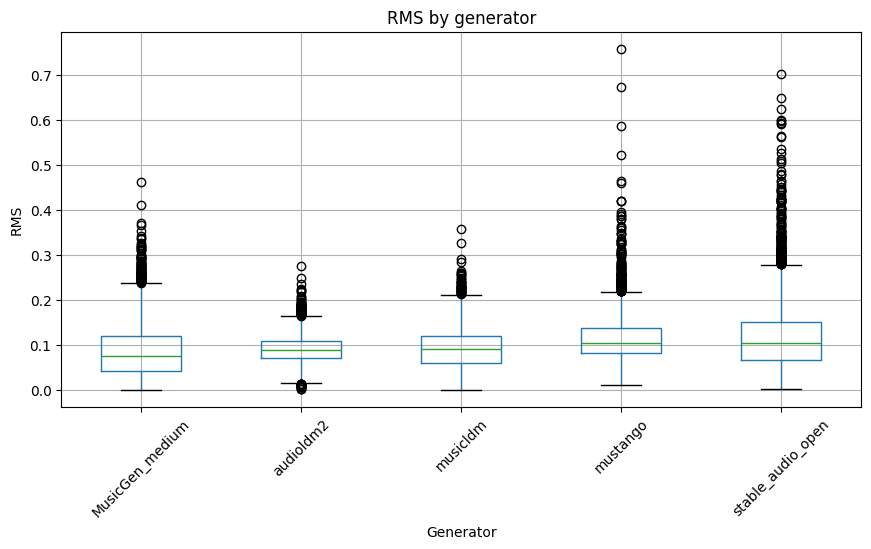

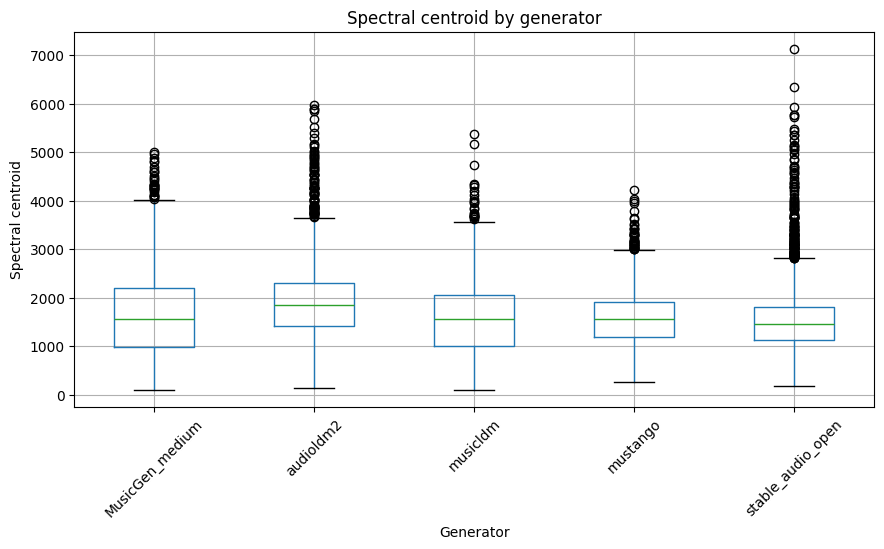

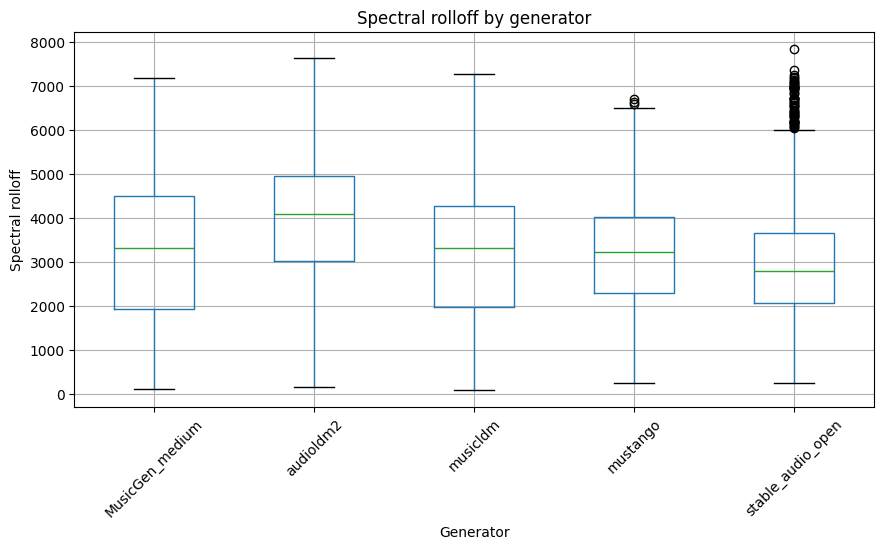

In [9]:
features_to_plot = [
    ("rms_mean", "RMS by generator", "RMS"),
    (
        "spectral_centroid_mean",
        "Spectral centroid by generator",
        "Spectral centroid"
    ),
    (
        "spectral_rolloff_mean",
        "Spectral rolloff by generator",
        "Spectral rolloff"
    ),
]

for feature, title, ylabel in features_to_plot:
    eda_df.boxplot(
        column=feature,
        by="generator",
        figsize=(10, 5),
    )

    plt.title(title)
    plt.suptitle("")
    plt.ylabel(ylabel)
    plt.xlabel("Generator")
    plt.xticks(rotation=45)
    plt.show()

### Acoustic feature observations

The results show several noticeable differences between the generators.

Stable Audio Open has the highest average RMS, while MusicGen Medium has the lowest. Mustango also has relatively high RMS values. This suggests that the generators differ in the typical energy level of the generated audio, so RMS can contain useful information for distinguishing between them. At the same time, the boxplot shows a large overlap between the distributions, which means that RMS alone wouldn't be enough for classification.

The spectral features show a clear pattern for AudioLDM2. It has the highest spectral centroid, spectral bandwidth, and spectral rolloff among all generators. This means that AudioLDM2 generates audio with more energy in higher frequencies and with a wider spread of frequencies.

Stable Audio Open on the other hand has the lowest spectral centroid and spectral rolloff. MusicLDM and Mustango are much closer to each other for these features, so separating these generators using only spectral centroid or rolloff would probably be more difficult.

Overall, the boxplots show that the generators have different acoustic tendencies, but their distributions still overlap. This suggests that these features can be useful for classification, especially when several of them are used together rather than separately.

### MFCC analysis

MFCCs describe the overall spectral shape and timbre of the audio signal.

Different MFCC coefficients capture different parts of the spectrum. 

We compare the first three MFCC values and then look more closely at MFCC 1, where the difference between generators is the most visible.

In [10]:
mfcc_features = [
    "mfcc_1_mean",
    "mfcc_2_mean",
    "mfcc_3_mean",
]

mfcc_summary = (
    eda_df
    .groupby("generator")[mfcc_features]
    .mean()
    .round(2)
)

mfcc_summary

,mfcc_1_mean,mfcc_2_mean,mfcc_3_mean
generator,,,
MusicGen_medium,-271.44,82.23,11.11
audioldm2,-160.98,76.91,4.51
musicldm,-202.33,98.90,-0.33
mustango,-153.65,103.81,-10.10
stable_audio_open,-259.97,79.91,-8.17


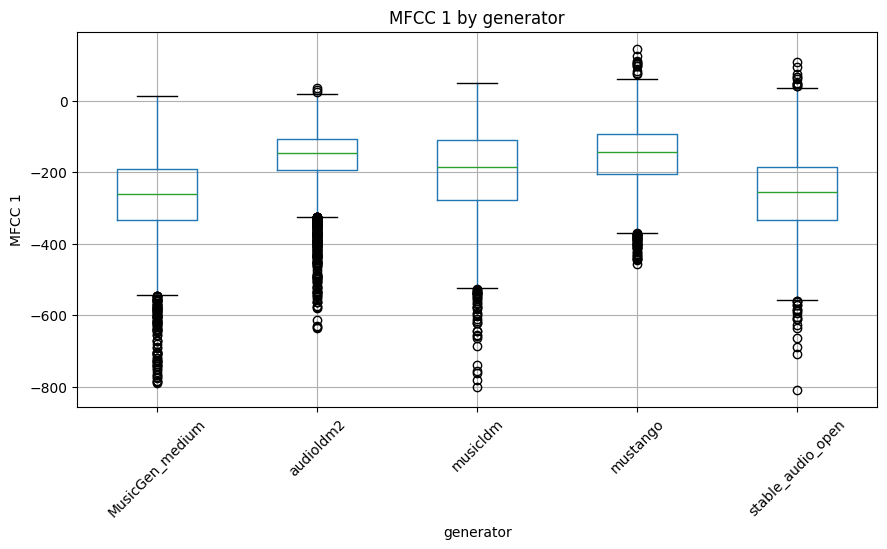

In [11]:
eda_df.boxplot(column="mfcc_1_mean", by="generator", figsize=(10, 5),)
plt.title("MFCC 1 by generator")
plt.suptitle("")
plt.ylabel("MFCC 1")
plt.xticks(rotation=45)
plt.show()

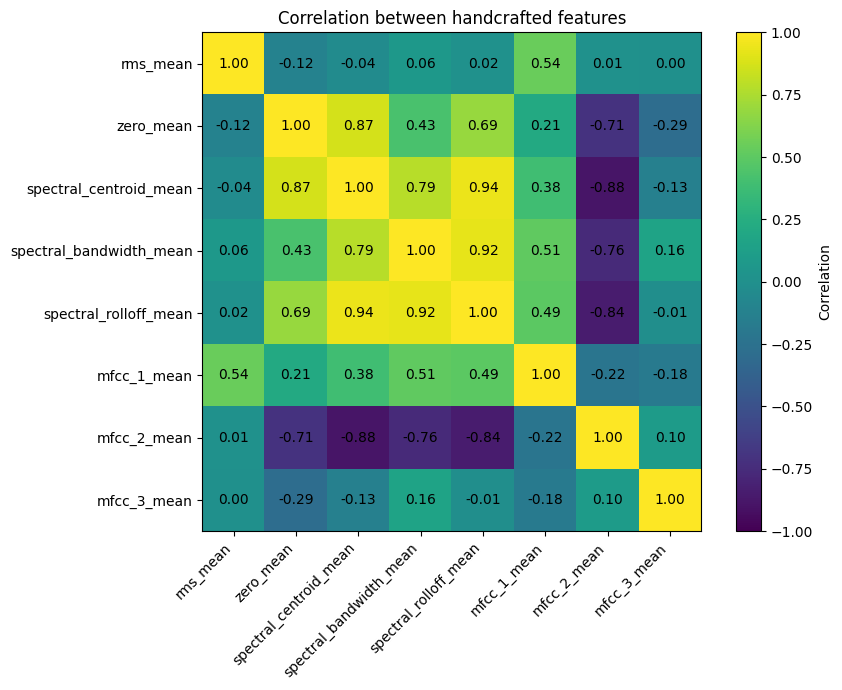

In [12]:
correlation_features = [
    "rms_mean",
    "zero_mean",
    "spectral_centroid_mean",
    "spectral_bandwidth_mean",
    "spectral_rolloff_mean",
    "mfcc_1_mean",
    "mfcc_2_mean",
    "mfcc_3_mean",
]

corr = eda_df[correlation_features].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=45,
    ha="right",
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features,
)

for i in range(len(correlation_features)):
    for j in range(len(correlation_features)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
        )

plt.title("Correlation between handcrafted features")
plt.tight_layout()
plt.show()

The correlation matrix shows that several spectral features are strongly related.

Spectral centroid and spectral rolloff have a strong positive correlation, and spectral bandwidth follows a similar pattern. This makes sense because all of these features describe the frequency distribution of the audio signal.

This also means that some of the handcrafted features may contain partly overlapping information. 

## Acoustic feature importance and ablation

The plots above describe feature distributions. Here we test predictive usefulness: a fixed Logistic Regression model is trained with different groups of features. Scaling and fitting happen only on train, and Macro F1 is measured on validation. A coefficient ranking is a property of this particular standardized linear model, not causal proof of acoustic fingerprints.

In [13]:
from sklearn.metrics import f1_score
from ai_music_origin.config import load_config
from ai_music_origin.models import build_logistic_regression

In [14]:
config = load_config(PROJECT_ROOT / 'config/default.yaml')
train_df = handcrafted_df.loc[handcrafted_df['split'] == 'train'].copy()
val_df = handcrafted_df.loc[handcrafted_df['split'] == 'validation'].copy()

In [15]:
energy_features = ['rms_mean', 'rms_std']
temporal_features = ['zero_mean', 'zero_std']  # ZCR statistics only
spectral_features = [
    'spectral_centroid_mean', 'spectral_centroid_std',
    'spectral_bandwidth_mean', 'spectral_bandwidth_std',
    'spectral_rolloff_mean', 'spectral_rolloff_std',
]
mfcc_features = [c for c in handcrafted_df if c.startswith('mfcc_')]
all_features = energy_features + temporal_features + spectral_features + mfcc_features
feature_groups = {
    'Energy': energy_features,
    'Temporal (ZCR)': temporal_features,
    'Spectral': spectral_features,
    'MFCC only': mfcc_features,
    'MFCC + Energy': mfcc_features + energy_features,
    'MFCC + Spectral': mfcc_features + spectral_features,
    'MFCC + Temporal': mfcc_features + temporal_features,
    'All features': all_features,
}

In [16]:
def evaluate_groups(groups):
    rows = []
    for group_name, columns in groups.items():
        estimator = build_logistic_regression(config)
        estimator.fit(train_df[columns], train_df['generator'])
        predictions = estimator.predict(val_df[columns])
        rows.append({
            'feature_group': group_name,
            'n_features': len(columns),
            'macro_f1': f1_score(val_df['generator'], predictions, average='macro'),
        })
    return pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
ablation_df = evaluate_groups(feature_groups)
display(ablation_df.round(4))

,feature_group,n_features,macro_f1
7,All features,36,0.7578
4,MFCC + Energy,28,0.7428
5,MFCC + Spectral,32,0.7384
6,MFCC + Temporal,28,0.7201
3,MFCC only,26,0.7145
2,Spectral,6,0.3808
0,Energy,2,0.3437
1,Temporal (ZCR),2,0.2271


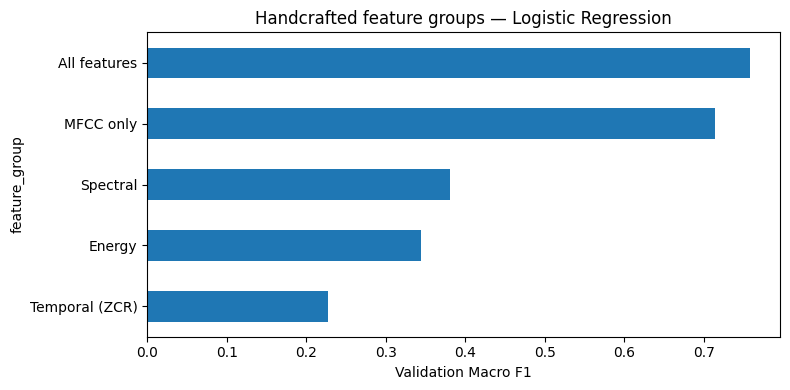

In [17]:
plot_order = ['Energy', 'Temporal (ZCR)', 'Spectral', 'MFCC only', 'All features']
main_groups = ablation_df.set_index('feature_group').loc[plot_order, 'macro_f1']
ax = main_groups.sort_values().plot.barh(figsize=(8, 4), legend=False)
ax.set_xlabel('Validation Macro F1')
ax.set_title('Handcrafted feature groups — Logistic Regression')
plt.tight_layout()
plt.show()

Inspecting the coefficients of one model trained on all 36 standardized features.

,feature,mean_absolute_coefficient
12,mfcc_2_mean,1.024
8,spectral_rolloff_mean,0.949
32,mfcc_12_mean,0.897
10,mfcc_1_mean,0.863
4,spectral_centroid_mean,0.802
5,spectral_centroid_std,0.741
34,mfcc_13_mean,0.694
11,mfcc_1_std,0.655
1,rms_std,0.647
28,mfcc_10_mean,0.574


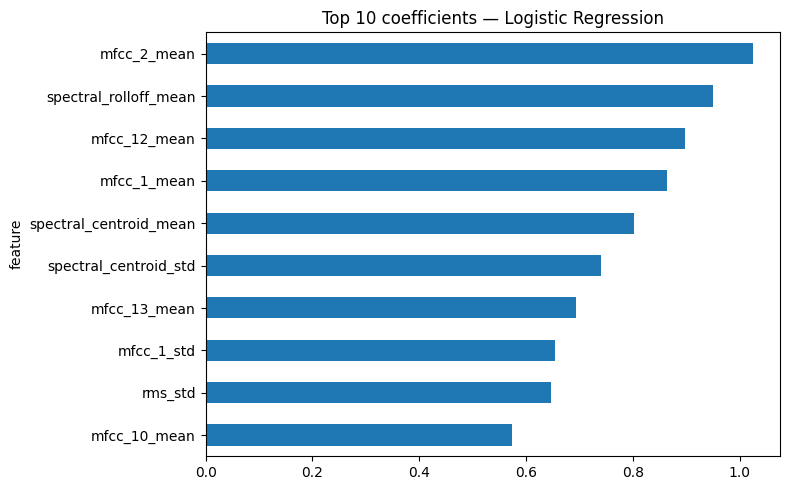

In [19]:
full_hc_model = build_logistic_regression(config)
full_hc_model.fit(train_df[all_features], train_df['generator'])
coef = full_hc_model.steps[-1][1].coef_
importance_df = (pd.DataFrame({
    'feature': all_features,
    'mean_absolute_coefficient': np.abs(coef).mean(axis=0),
}).sort_values('mean_absolute_coefficient', ascending=False))
display(importance_df.head(10).round(3))
ax = (importance_df.head(10).sort_values('mean_absolute_coefficient')
      .plot.barh(x='feature', y='mean_absolute_coefficient', legend=False, figsize=(8, 5)))
ax.set_title('Top 10 coefficients — Logistic Regression')
plt.tight_layout()
plt.show()

## Conclusions
The ablation experiments show that MFCC features are the most informative individual group (`Macro F1 = 0.7145`), while combining all 36 handcrafted features achieves the best result (0.7578). This suggests that generator-specific acoustic information is distributed across multiple feature groups rather than captured by a single characteristic.

The coefficient analysis also highlights `mfcc_2_mean` and `spectral_rolloff_mean` as the most influential features in our Logistic Regression model. However, these coefficients reflect the model's learned weights, not necessarily unique acoustic fingerprints of the generators.

## Embeddings: extraction and visualization
### 1. CLAP - audio–text contrastive representation

[CLAP](https://huggingface.co/laion/clap-htsat-unfused) aligns audio and language through contrastive pretraining, yielding a general-purpose embedding that summarizes semantic and acoustic information. It is a natural baseline representation for our text-to-music dataset, whose tracks originate from captions. The selected checkpoint is laion/clap-htsat-unfused (512-dimensional audio embeddings).

The embeddings file is reused if present. To deliberately re-extract, set `RECOMPUTE_CLAP=True` above. PCA and UMAP are exploratory plots; no PCA/UMAP transformation is fed to the baseline classifiers.

In [ ]:
if RECOMPUTE_CLAP or not CLAP_PATH.exists():
    import librosa
    import torch
    from tqdm.auto import tqdm
    from transformers import ClapModel, ClapProcessor
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    MODEL_NAME = 'laion/clap-htsat-unfused'
    processor = ClapProcessor.from_pretrained(MODEL_NAME)
    clap_model = ClapModel.from_pretrained(MODEL_NAME).to(device)
    clap_model.eval()

    def extract_clap_embedding(audio_path):
        audio, sr = load_audio(audio_path)
        audio = preprocess_audio(audio, sample_rate=sr, target_duration=10.0, normalize=False)
        target_sr = processor.feature_extractor.sampling_rate
        if sr != target_sr:
            audio = librosa.resample(audio, orig_sr=sr, target_sr=target_sr)
        inputs = processor(audio=audio, sampling_rate=target_sr, return_tensors='pt')
        inputs = {key: value.to(device) for key, value in inputs.items()}
        with torch.inference_mode():
            output = clap_model.get_audio_features(**inputs)
        return output.pooler_output.cpu().numpy().squeeze(0)

    embeddings = np.stack([
        extract_clap_embedding(audio_path)
        for audio_path in tqdm(dataset_df['path'], desc='CLAP embeddings')
    ])
    CLAP_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        CLAP_PATH, embeddings=embeddings,
        track_ids=dataset_df['track_id'].astype(str).to_numpy(),
        generators=dataset_df['generator'].to_numpy(),
        splits=dataset_df['split'].to_numpy()
    )

with np.load(CLAP_PATH, allow_pickle=True) as saved:
    embeddings = saved['embeddings']
    labels = saved['generators'].astype(str)
print('CLAP representation:', embeddings.shape)

CLAP representation: (27605, 512)


### 2. MERT-v1-95M embeddings: alternative pretrained representation
[MERT-v1-95M](https://huggingface.co/m-a-p/MERT-v1-95M) is trained to model music audio with a masked-prediction, self-supervised objective rather than audio–text alignment. Comparing it with CLAP tests whether a music-focused acoustic representation is more informative for generator attribution. The 95M-parameter checkpoint is a relatively compact choice (768-dimensional hidden states, 24 kHz, 5-second pretraining context).

If `mert_embeddings_full.npz` or `mert_embeddings.npz` for pilot set already exists, skip the extraction cells and use the shared plotting section below.

In [37]:
MERT_MODEL_NAME = "m-a-p/MERT-v1-95M"
MERT_PATH = PROJECT_ROOT / "data" / "interim" / f"mert_embeddings{suffix}.npz"
MERT_PROGRESS_PATH = PROJECT_ROOT / "data" / "interim" / f"mert_embeddings{suffix}.progress.npz"
MERT_TARGET_SR = 24_000
MERT_CHUNK_SECONDS = 5
MERT_DIM = 768

In [ ]:
expected_ids = np.asarray(dataset_df["track_id"].astype(str).tolist(), dtype=str)
expected_generators = np.asarray(dataset_df["generator"].astype(str).tolist(), dtype=str)
expected_splits = np.asarray(dataset_df["split"].astype(str).tolist(), dtype=str)
print("Selected dataset:", len(dataset_df), "clips")

Selected dataset: 3000 clips


In [ ]:
if RUN_MERT_SMOKE_TEST or RUN_MERT_EXTRACTION:
    import torch
    import librosa
    from tqdm.auto import tqdm
    from transformers import AutoModel, Wav2Vec2FeatureExtractor

    mert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("MERT device:", mert_device)
    mert_processor = Wav2Vec2FeatureExtractor.from_pretrained(MERT_MODEL_NAME)
    mert_model = AutoModel.from_pretrained(MERT_MODEL_NAME, trust_remote_code=True).to(mert_device).eval()

    def extract_mert_embedding(audio_path):
        audio, sr = load_audio(audio_path)
        audio = preprocess_audio(audio, sample_rate=sr, target_duration=10.0, normalize=False)
        if sr != MERT_TARGET_SR:
            audio = librosa.resample(np.asarray(audio, dtype=np.float32), orig_sr=sr, target_sr=MERT_TARGET_SR)
        else:
            audio = np.asarray(audio, dtype=np.float32)

        target_samples = 2 * MERT_CHUNK_SECONDS * MERT_TARGET_SR
        audio = np.pad(audio[:target_samples], (0, max(0, target_samples - len(audio))))
        chunks = audio.reshape(2, MERT_CHUNK_SECONDS * MERT_TARGET_SR)
        inputs = mert_processor([chunks[0], chunks[1]], sampling_rate=MERT_TARGET_SR, padding=True, return_tensors="pt",)
        inputs = {name: value.to(mert_device) for name, value in inputs.items()}
        with torch.inference_mode():
            output = mert_model(**inputs)
            feature = output.last_hidden_state.mean(dim=1).mean(dim=0)
        embedding = feature.float().cpu().numpy()
        if embedding.shape != (MERT_DIM,) or not np.isfinite(embedding).all():
            raise ValueError(f"Unexpected MERT embedding shape/values: {embedding.shape}")
        return embedding

    if RUN_MERT_SMOKE_TEST:
        demo_vector = extract_mert_embedding(dataset_df.iloc[0]["path"])
        print("MERT smoke-test shape:", demo_vector.shape)
        print("Finite:", bool(np.isfinite(demo_vector).all()))
else:
    print("MERT extraction disabled. Set RUN_MERT_SMOKE_TEST=True to check one clip.")


MERT smoke-test shape: (768,)
Finite: True


In [ ]:
if RUN_MERT_EXTRACTION:
    if MERT_PATH.exists() and not RECOMPUTE_MERT:
        print("Existing complete MERT file found; not recomputing:", MERT_PATH)
    else:
        vectors = np.empty((len(dataset_df), MERT_DIM), dtype=np.float32)
        start = 0
        if MERT_PROGRESS_PATH.exists() and not RECOMPUTE_MERT:
            with np.load(MERT_PROGRESS_PATH, allow_pickle=False) as checkpoint:
                old_vectors = checkpoint["embeddings"]
                start = len(old_vectors)
                assert checkpoint["model_name"].item() == MERT_MODEL_NAME
                assert np.array_equal(checkpoint["track_ids"], expected_ids[:start])
                assert np.array_equal(checkpoint["generators"], expected_generators[:start])
                assert np.array_equal(checkpoint["splits"], expected_splits[:start])
                assert old_vectors.shape == (start, MERT_DIM)
                vectors[:start] = old_vectors
            print("Resuming from saved MERT embeddings:", start)

        for i in tqdm(range(start, len(dataset_df)), desc="MERT embeddings"):
            vectors[i] = extract_mert_embedding(dataset_df.iloc[i]["path"])
            next_index = i + 1
            if next_index % MERT_CHECKPOINT_EVERY == 0:
                np.savez_compressed(
                    MERT_PROGRESS_PATH,
                    embeddings=vectors[:next_index],
                    track_ids=expected_ids[:next_index],
                    generators=expected_generators[:next_index],
                    splits=expected_splits[:next_index],
                    model_name=np.array(MERT_MODEL_NAME),
                )

        np.savez_compressed(
            MERT_PATH,
            embeddings=vectors,
            track_ids=expected_ids,
            generators=expected_generators,
            splits=expected_splits,
            model_name=np.array(MERT_MODEL_NAME),
            pooling=np.array("mean(last-layer over frames) then mean(two 5s chunks)"),
        )
        MERT_PROGRESS_PATH.unlink(missing_ok=True)

if MERT_PATH.exists():
    with np.load(MERT_PATH, allow_pickle=False) as saved:
        mert_embeddings = saved["embeddings"]
        assert mert_embeddings.shape == (len(dataset_df), MERT_DIM)
        assert np.array_equal(saved["track_ids"].astype(str), expected_ids)
        assert np.array_equal(saved["generators"].astype(str), expected_generators)
        assert np.array_equal(saved["splits"].astype(str), expected_splits)
        assert np.isfinite(mert_embeddings).all()
    print("MERT representation:", mert_embeddings.shape)
else:
    print("No complete MERT file yet; smoke-test or extract before notebook 03.")


MERT representation: (3000, 768)


### 3. MuQ - music self-supervised representation with Mel-RVQ
[MuQ-large-msd-iter](https://github.com/tencent-ailab/MuQ) is another pretrained, audio-only music representation model. Unlike CLAP, it is not trained to match text; unlike MERT, it uses Mel residual vector quantization (Mel-RVQ) targets as part of its music self-supervised learning. The released checkpoint has approximately 300M parameters, needs 24 kHz audio and yields 1,024-dimensional last-layer features in our extraction.

If `muq_embeddings_full.npz` or `muq_embeddings.npz` for pilot set already exists, skip the extraction cells and use the shared plotting section below.


In [15]:
MUQ_MODEL_NAME = "OpenMuQ/MuQ-large-msd-iter"
MUQ_PATH = PROJECT_ROOT / "data" / "interim" / f"muq_embeddings{suffix}.npz"
MUQ_PROGRESS_PATH = PROJECT_ROOT / "data" / "interim" / f"muq_embeddings{suffix}.progress.npz"
MUQ_TARGET_SR = 24_000
MUQ_CHUNK_SECONDS = 5

print("Selected clips:", len(dataset_df))

Selected clips: 27605


In [ ]:
muq_expected_ids = dataset_df["track_id"].astype(str).to_numpy()
muq_expected_generators = dataset_df["generator"].astype(str).to_numpy()
muq_expected_splits = dataset_df["split"].astype(str).to_numpy()
muq_needs_model = RUN_MUQ_SMOKE_TEST or (RUN_MUQ_EXTRACTION and (RECOMPUTE_MUQ or not MUQ_PATH.exists()))

if muq_needs_model:
    import torch
    import librosa
    from tqdm.auto import tqdm
    from muq import MuQ
    from easydict import EasyDict

    muq_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("MuQ device:", muq_device)
    if muq_device.type == "cpu":
        print("Warning: MuQ-large extraction on CPU may be very slow.")
    muq_model = MuQ.from_pretrained(MUQ_MODEL_NAME).to(muq_device).float().eval()
    patched_configs = []
    for module_name, module in muq_model.named_modules():
        for attr_name in ("config", "cfg"):
            config = getattr(module, attr_name, None)
            if isinstance(config, EasyDict):
                if "_attn_implementation" not in config:
                    config._attn_implementation = "eager"
                    patched_configs.append(module_name)
    print("Patched MuQ configs:", patched_configs)
    from easydict import EasyDict

    updated_configs = []
    for module_name, module in muq_model.named_modules():
        config = getattr(module, "config", None)
        if isinstance(config, EasyDict):
            config.output_hidden_states = True
            updated_configs.append(module_name)
    print("Enabled hidden states for:", updated_configs)

    def extract_muq_embedding(audio_path):
        audio, sr = load_audio(audio_path)
        audio = preprocess_audio(audio, sample_rate=sr,target_duration=10.0, normalize=False)
        audio = np.asarray(audio, dtype=np.float32)
        if sr != MUQ_TARGET_SR:
            audio = librosa.resample(audio, orig_sr=sr, target_sr=MUQ_TARGET_SR)

        samples_per_chunk = MUQ_CHUNK_SECONDS * MUQ_TARGET_SR
        needed = 2 * samples_per_chunk
        audio = np.pad(audio[:needed], (0, max(0, needed - len(audio))))
        chunks = audio.reshape(2, samples_per_chunk)
        wavs = torch.as_tensor(chunks, dtype=torch.float32, device=muq_device)

        with torch.inference_mode():
            output = muq_model(wavs, output_hidden_states=True)
            vector = output.last_hidden_state.mean(dim=1).mean(dim=0)
        vector = vector.float().cpu().numpy().astype(np.float32)
        if vector.ndim != 1 or not np.isfinite(vector).all():
            raise ValueError(f"Invalid MuQ embedding: {vector.shape}")
        return vector

    muq_demo_vector = extract_muq_embedding(dataset_df.iloc[0]["path"])
    print("MuQ smoke-test shape:", muq_demo_vector.shape)

if RUN_MUQ_EXTRACTION and (RECOMPUTE_MUQ or not MUQ_PATH.exists()):
    muq_dim = len(muq_demo_vector)
    vectors = np.empty((len(dataset_df), muq_dim), dtype=np.float32)
    start = 0

    if MUQ_PROGRESS_PATH.exists() and not RECOMPUTE_MUQ:
        with np.load(MUQ_PROGRESS_PATH, allow_pickle=False) as checkpoint:
            old = checkpoint["embeddings"]
            start = len(old)
            vectors[:start] = old
        print("Resuming MuQ from:", start)

    for i in tqdm(range(start, len(dataset_df)), desc="MuQ embeddings"):
        vectors[i] = muq_demo_vector if i == 0 else extract_muq_embedding(dataset_df.iloc[i]["path"])
        completed = i + 1
        if completed % MUQ_CHECKPOINT_EVERY == 0:
            np.savez_compressed(
                MUQ_PROGRESS_PATH,
                embeddings=vectors[:completed],
                track_ids=muq_expected_ids[:completed],
                generators=muq_expected_generators[:completed],
                splits=muq_expected_splits[:completed],
                model_name=np.array(MUQ_MODEL_NAME),
            )

    MUQ_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        MUQ_PATH,
        embeddings=vectors,
        track_ids=muq_expected_ids,
        generators=muq_expected_generators,
        splits=muq_expected_splits,
        model_name=np.array(MUQ_MODEL_NAME),
        pooling=np.array("last-layer mean over frames, then mean over two 5s chunks"),
    )
    MUQ_PROGRESS_PATH.unlink(missing_ok=True)
    print("Saved complete MuQ embeddings:", MUQ_PATH)

if MUQ_PATH.exists():
    with np.load(MUQ_PATH, allow_pickle=False) as saved:
        muq_embeddings = saved["embeddings"]
    print("MuQ representation:", muq_embeddings.shape)
else:
    print("No complete MuQ file yet. Set RUN_MUQ_SMOKE_TEST, then RUN_MUQ_EXTRACTION.")

## Shared PCA and UMAP: CLAP vs MERT vs MuQ

Now that we have pretrained embeddings for all three representations, we compare their geometry on exactly the same audio examples by explore whether generator labels show any visible structure in each embedding space.
- PCA finds linear directions of highest variance. The fraction explained by PC1 + PC2 tells us how much information in the embedding variance is displayed in the two-dimensional plot.
- UMAP is a non-linear neighborhood visualization. We use n_neighbors=15, min_dist=0.1, metric="cosine" and a fixed random seed for each representation. The UMAP axes have no physical interpretation, and distances between disconnected groups can be misleading.
- L2-normalization is applied to each representation separately, and the identical subset of audio clips is used across all six panels. We preserve colors for generator identities but do not compare raw axis positions between separate PCA/UMAP fits.

In [2]:
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
import seaborn as sns
import umap

In [8]:
representation_paths = {
    "CLAP": PROJECT_ROOT / "data/interim" / f"clap_embeddings{suffix}.npz",
    "MERT": PROJECT_ROOT / "data/interim" / f"mert_embeddings{suffix}.npz",
    "MuQ": PROJECT_ROOT / "data/interim" / f"muq_embeddings{suffix}.npz",
}

def load_aligned_embeddings(npz_path, metadata):
    if not npz_path.is_file():
        raise FileNotFoundError(f"Embedding file missing: {npz_path}")

    with np.load(npz_path, allow_pickle=True) as saved:
        keys = set(saved.files)
        needed = {"embeddings", "track_ids", "generators", "splits"}
        if not needed <= keys:
            raise ValueError(f"Missing NPZ arrays in {npz_path.name}: {needed - keys}")
        vectors = np.asarray(saved["embeddings"], dtype=np.float32)
        ids = np.asarray(saved["track_ids"], dtype=str)
        gens = np.asarray(saved["generators"], dtype=str)
        splits = np.asarray(saved["splits"], dtype=str)

    stored_keys = pd.MultiIndex.from_arrays([ids, gens, splits])
    wanted_keys = pd.MultiIndex.from_frame(metadata[["track_id", "generator", "split"]].astype(str))
    pos = stored_keys.get_indexer(wanted_keys)
    if len(vectors) != len(metadata) or (pos < 0).any():
        raise ValueError(f"File {npz_path.name} does not contain exactly the chosen "
                          f"{DATASET_MODE} dataset; check suffix and splits.")
    return vectors[pos]

representations = {name: load_aligned_embeddings(path, dataset_df) for name, path in representation_paths.items()}
for name, matrix in representations.items():
    print(f"{name}: {matrix.shape}, aligned to {DATASET_MODE} metadata")


CLAP: (27605, 512), aligned to full metadata
MERT: (27605, 768), aligned to full metadata
MuQ: (27605, 1024), aligned to full metadata


In [14]:
labels_all = dataset_df["generator"].astype(str).to_numpy()
all_indices = np.arange(len(dataset_df))
vis_idx = all_indices
labels_vis = labels_all[vis_idx]
print("Samples shown in each figure:", len(vis_idx))
print("Samples by generator:", pd.Series(labels_vis).value_counts().to_dict())
pca_positions = {}
umap_positions = {}
pca_stats = []
for name, full_vectors in representations.items():
    X = normalize(full_vectors[vis_idx], norm="l2")
    pca = PCA(n_components=2, random_state=42)
    pca_positions[name] = pca.fit_transform(X)
    pca_stats.append({
        "representation": name,
        "dimension": X.shape[1],
        "PC1 (%)": round(100 * pca.explained_variance_ratio_[0], 2),
        "PC2 (%)": round(100 * pca.explained_variance_ratio_[1], 2),
        "PC1 + PC2 (%)": round(100 * pca.explained_variance_ratio_.sum(), 2),
    })
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42)
    umap_positions[name] = reducer.fit_transform(X)
pca_summary = pd.DataFrame(pca_stats).set_index("representation")
display(pca_summary)


Samples shown in each figure: 27605
Samples by generator: {'MusicGen_medium': 5521, 'audioldm2': 5521, 'musicldm': 5521, 'mustango': 5521, 'stable_audio_open': 5521}


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,dimension,PC1 (%),PC2 (%),PC1 + PC2 (%)
representation,,,,
CLAP,512,11.720000,9.28,21.000000
MERT,768,16.530001,9.45,25.969999
MuQ,1024,16.540001,13.16,29.700001


Saved comparison figure: d:\UCU\33333333333333333\AI\AI-vs-Original-Music-Classification\results\pca_umap_clap_mert_muq_full.png


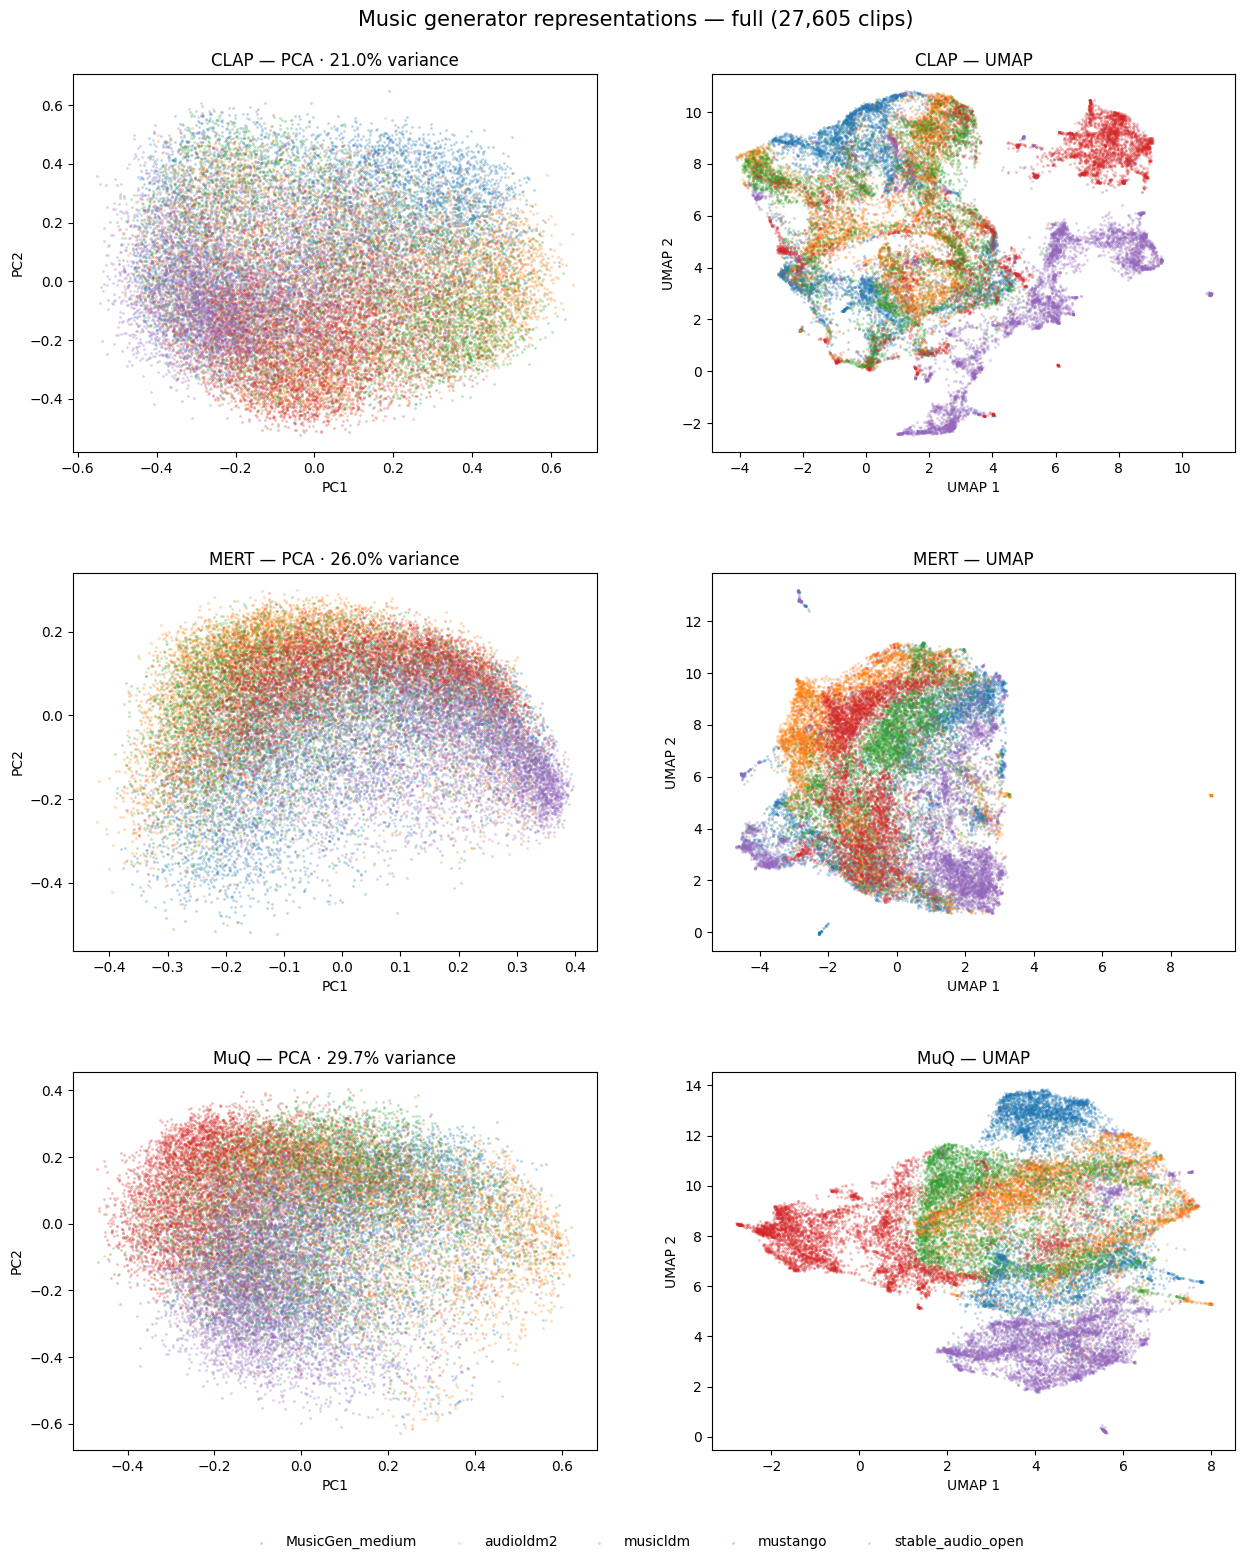

In [11]:
# Same generators/colors, consistent marker size and transparency in every panel.
plot_names = list(representations)
generators = sorted(np.unique(labels_vis).tolist())
palette = dict(zip(generators, sns.color_palette("tab10", len(generators))))
point_size = 4 if len(vis_idx) > 8_000 else 9
point_alpha = 0.30 if len(vis_idx) > 8_000 else 0.55

fig, axes = plt.subplots(len(plot_names), 2, figsize=(15, 16))
for row, name in enumerate(plot_names):
    for col, (technique, coords) in enumerate([
        ("PCA", pca_positions[name]),
        ("UMAP", umap_positions[name]),
    ]):
        ax = axes[row, col]
        for generator in generators:
            mask = labels_vis == generator
            ax.scatter(coords[mask, 0], coords[mask, 1], s=point_size, alpha=point_alpha, color=palette[generator], label=generator, linewidths=0, rasterized=True)
        explained = f" · {pca_summary.loc[name, 'PC1 + PC2 (%)']:.1f}% variance" if technique == "PCA" else ""
        ax.set_title(f"{name} — {technique}{explained}")
        ax.set_xlabel("PC1" if technique == "PCA" else "UMAP 1")
        ax.set_ylabel("PC2" if technique == "PCA" else "UMAP 2")

handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, 0.01), ncol=min(len(generators), 5), frameon=False)
fig.suptitle(f"Music generator representations — {DATASET_MODE} ({len(vis_idx):,} clips)", fontsize=15)
fig.subplots_adjust(top=0.94, bottom=0.08, hspace=0.32, wspace=0.22)
PLOT_PATH = PROJECT_ROOT / "results" / f"pca_umap_clap_mert_muq_{DATASET_MODE}.png"
PLOT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(PLOT_PATH, dpi=170, bbox_inches="tight")
print("Saved comparison figure:", PLOT_PATH)
plt.show()


### Conclusions: PCA and UMAP comparison

We visualized all **27,605 audio clips** using CLAP, MERT, and MuQ embeddings. PCA explains 21.0% of the variance for CLAP, 26.0% for MERT, and 29.7% for MuQ. However, all three PCA plots show substantial overlap between generators, suggesting that their differences are not clearly captured by just two linear components.

UMAP reveals more noticeable generator-specific patterns:

- **CLAP** shows relatively distinct regions for Mustango and Stable Audio Open, while MusicGen, AudioLDM2, and MusicLDM overlap considerably.
- **MERT** produces a more mixed distribution, although some regions contain higher concentrations of particular generators.
- **MuQ** shows more pronounced generator-associated regions, especially for Mustango, Stable Audio Open, and MusicGen. However, some overlap remains.

**Overall, the results suggest that pretrained audio embeddings capture generator-related characteristics, but none achieves complete separation in 2D.** MuQ appears to provide more visually structured groups, while CLAP also distinguishes certain generators effectively.
